# Brest : vagues de chaleur et extrêmes annuels jusqu'en 2100

**Projet SMA, TAF MCE, 2026–2027 — Pierre Tandeo. Rendu commun du 27 octobre 2026.**

Nous cherchons à distinguer ce que les données montrent déjà de ce qu'un
modèle permet de projeter. La première partie décrit les épisodes chauds de
1940 à 2025. La seconde compare des lois de température annuelle conditionnées
au CO₂, puis les applique aux trois scénarios fournis jusqu'en 2100.

| Contribution | Travail intégré |
|---|---|
| Elias | Pipeline, références, DDPM, débruiteur stochastique, ablations et validation |
| Christian | Régression bayésienne à pente positive et incertitude conjointe des paramètres |
| Reda | Statistiques des vagues, GEV non stationnaire et bootstrap |
| Yazid | Transformations et régression quantile sur le CO₂ |

Le cinquième membre n'a pas fourni de contribution au moment de ce rendu.
Nous ne lui attribuons pas un travail fictif. Les notebooks individuels et les
résultats historiques sont conservés dans le dépôt. L'intégration corrige les
écarts de données et de validation sans imposer la même architecture aux méthodes.

**Point de transparence : le test 2001–2025 a déjà été consulté.** Les essais
ajoutés ici sont exploratoires. Leurs réglages utilisent uniquement les
validations antérieures à 2001 ; cela ne transforme pas ce test en nouvelle
preuve indépendante. Nous distinguons le choix sur validation, le meilleur
score observé sur test et le réajustement complet destiné aux projections.

## 1. Exécuter ce notebook dans Colab ou Jupyter

**Mode rapide** : laisser `MODE="rapide"`, puis redémarrer et tout exécuter.
Les données, petits états de modèles et tableaux d'expériences sont embarqués
dans le notebook. Le code recalcule le cycle saisonnier, les événements,
les prévisions de la sélection, le benchmark et les figures. Il ne dépend
d'aucun chemin personnel ni d'un accès au dépôt GitHub.

**Mode réentraînement** : choisir `MODE="reentrainement"` et, dans Colab,
activer un GPU. Toutes les familles, les trois validations et les ajustements
sont reconstruits dans un dossier distinct. Le calcul est sensiblement plus
long que le mode rapide, car les réseaux historiques ne sont plus réutilisés.
Les tableaux affichés utilisent alors cette nouvelle exécution. Les scores
historiques présentés dans les commentaires restent explicitement identifiés.

La cellule suivante installe seulement les dépendances absentes. L'archive
technique est repliée pour garder le raisonnement lisible ; les équations et
le code essentiel sont développés dans les sections suivantes. Les sorties
enregistrées ne remplacent pas une exécution depuis un noyau neuf.

In [1]:
import os, sys, time, importlib.util, subprocess
from pathlib import Path
DEBUT_EXECUTION = time.perf_counter()
MODE = os.environ.get("SMA_MODE", "rapide")  #@param ["rapide", "reentrainement"]
assert MODE in ("rapide", "reentrainement")
dependances = {"numpy":"numpy==2.3.5", "pandas":"pandas==2.3.3",
    "scipy":"scipy==1.16.3", "matplotlib":"matplotlib==3.10.8",
    "sklearn":"scikit-learn==1.9.1", "torch":"torch>=2.5", "yaml":"PyYAML==6.0.2"}
absentes = [paquet for module, paquet in dependances.items()
            if importlib.util.find_spec(module) is None]
if absentes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *absentes])
print("Mode :", MODE, "— Python", sys.version.split()[0])

Mode : rapide — Python 3.12.10


In [2]:
#@title Ressources embarquées : données, poids et résultats vérifiables
import base64, hashlib, io, json, tempfile, zipfile
ARCHIVE_BASE64 = "..."
archive = base64.b64decode(ARCHIVE_BASE64)
assert hashlib.sha256(archive).hexdigest() == "ded9f41bf2323207ac1a854e0892298e801981859c3242d43dbb28b85764f31c"
RACINE = Path(tempfile.mkdtemp(prefix="sma_brest_"))
with zipfile.ZipFile(io.BytesIO(archive)) as z:
    for nom in z.namelist():
        (RACINE / nom).resolve().relative_to(RACINE.resolve())
    z.extractall(RACINE)
empreintes = json.loads((RACINE / "MANIFEST_EMBARQUE.json").read_text())
for nom, attendu in empreintes.items():
    assert hashlib.sha256((RACINE / nom).read_bytes()).hexdigest() == attendu, nom
sys.path.insert(0, str(RACINE / "src"))
print(len(empreintes), "ressources vérifiées ; archive", "ded9f41bf2323207")

251 ressources vérifiées ; archive ded9f41bf2323207


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import beta
from IPython.display import display, Markdown
from sma.final_models import predictive_sample, SCENARIOS
from sma.diagnostics import evaluate
torch.set_num_threads(1)
plt.rcParams.update({"figure.figsize":(10,4), "axes.grid":True, "grid.alpha":.2})
DONNEES = RACINE / "rendu_final/data"
RESULTATS = RACINE / "rendu_final/resultats"
MODELES = RACINE / "rendu_final/modeles"
if MODE == "reentrainement":
    # La matrice complète est exécutée : cette cellule attend sa terminaison.
    subprocess.check_call([sys.executable, str(RACINE/"scripts/run_final_team.py"),
        "--retrain", "--output", str(RACINE/"reentrainement")], cwd=RACINE,
        env={**os.environ, "PYTHONIOENCODING":"utf-8"})
    RESULTATS = RACINE / "reentrainement/resultats"
    MODELES = RACINE / "reentrainement/modeles"
choix = json.loads((RESULTATS/"selection.json").read_text())
def tableau(frame):
    noms={"variable":"Variable", "model":"Modèle", "crps":"CRPS (°C)",
        "twcrps":"twCRPS (°C)", "coverage80":"Couverture 80 %", "width80":"Largeur 80 % (°C)",
        "bias":"Biais (°C)", "scenario":"Scénario", "p_2100":"P en 2100", "p_at_least_one":"P au moins une fois"}
    display(frame.rename(columns=noms).round(4))
daily = pd.read_csv(DONNEES/"daily_temp_brest.csv", parse_dates=["valid_time"])
annual = pd.read_csv(DONNEES/"yearly_temp_brest.csv", parse_dates=["valid_time"])
annual["year"] = annual.valid_time.dt.year
train = pd.read_csv(DONNEES/"yearly_temp_brest_train.csv", parse_dates=["valid_time"])
inputs = pd.read_csv(DONNEES/"test_inputs.csv", parse_dates=["valid_time"])
future = pd.read_csv(DONNEES/"yearly_future_co2.csv", parse_dates=["valid_time"])
assert len(annual)==86 and len(train)==61 and len(inputs)==25 and len(future)==75
assert daily.valid_time.is_unique and daily["mean"].notna().all()
assert np.all(daily.valid_time.diff().dropna()==pd.Timedelta(days=1))
tableau(pd.DataFrame({"Données":["Moyennes journalières", "Extrêmes annuels", "CO₂ futur"],
    "Lignes":[len(daily),len(annual),len(future)],
    "Période":["1940–2025", "1940–2025", "2026–2100"], "Unités":["°C", "°C ; ppm", "ppm"]}))

,Données,Lignes,Période,Unités
0,Moyennes journalières,31412,1940–2025,°C
1,Extrêmes annuels,86,1940–2025,°C ; ppm
2,CO₂ futur,75,2026–2100,ppm


### Provenance et sens des variables

Nous utilisons exclusivement les CSV du professeur et leur découpage par le
kit du groupe. Le maximum annuel est le pic de température de l'année ; il
ne se déduit pas du maximum des moyennes sur 24 heures. Les moyennes
journalières servent uniquement à la première partie.

Le sujet présente les données comme ERA5 à 9 km. Les CSV ne permettent pas
de certifier le produit ni la maille : la documentation distingue ERA5 et
ERA5-Land, dont la résolution native est 9 km. Nous parlons donc de la série
fournie pour Brest, sans convertir ses extrêmes en records de station.
Une maille et une station ne représentent pas exactement la même variable.
[Documentation ECMWF sur ERA5-Land](https://www.ecmwf.int/en/era5-land).

Les scénarios donnent des **concentrations de CO₂ en ppm**. Le nombre 8,5 de
SSP5-8.5 désigne un niveau de forçage en W/m², pas une concentration ni une
probabilité du scénario. Nous ne leur attribuons pas de poids probabilistes.

## 2. Partie 1 — Le cycle saisonnier

Pour chaque mois/jour, nous estimons q10, q50 et q90 sur les 86 années. Nous
lissons les trois quantiles avec une fenêtre centrée de 31 jours, circulaire
entre décembre et janvier. Le 29 février est exclu de cette climatologie à
365 jours, puis son seuil est interpolé entre le 28 février et le 1er mars.
Ainsi, une suite de jours chauds conserve sa vraie durée calendaire.

$$\widetilde q_p(j)=\frac1{31}\sum_{k=-15}^{15}q_p(j+k\pmod {365}).$$

Cette climatologie est **descriptive sur 1940–2025**. Elle ne sert pas à
sélectionner les modèles annuels. Elle mesure les anomalies à une référence
commune ; elle n'est pas une normale climatique mobile.

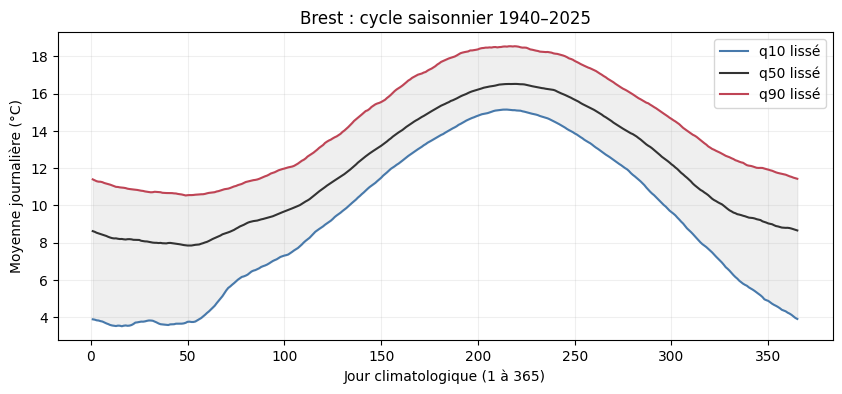

La médiane lissée va de **7.8 à 16.5 °C**, soit une amplitude de 8.7 °C. Son maximum est le 08-07. Le maximum tardif et la faible amplitude sont compatibles avec l'inertie thermique de l'océan. Cette figure décrit une saisonnalité ; elle ne permet pas, seule, d'attribuer ses causes.

In [4]:
jours = daily.copy()
jours["mois_jour"] = jours.valid_time.dt.strftime("%m-%d")
calendrier = pd.date_range("2001-01-01", "2001-12-31").strftime("%m-%d")
brut = (jours[jours.mois_jour!="02-29"].groupby("mois_jour")["mean"]
        .quantile([.1,.5,.9]).unstack().reindex(calendrier))
brut.columns = ["q10", "q50", "q90"]
cycle = pd.DataFrame(index=calendrier)
for nom in brut:
    cycle[nom] = np.convolve(np.pad(brut[nom],(15,15),mode="wrap"), np.ones(31)/31, mode="valid")
    seuil = cycle[nom].to_dict()
    seuil["02-29"] = (seuil["02-28"]+seuil["03-01"])/2
    jours[nom] = jours.mois_jour.map(seuil)
assert np.all(cycle.q10<=cycle.q50) and np.all(cycle.q50<=cycle.q90)
fig, ax = plt.subplots()
for nom,col in zip(cycle,["#4779ab","#333333","#bf4455"]):
    ax.plot(range(1,366),cycle[nom],label=nom+" lissé",color=col)
ax.fill_between(range(1,366),cycle.q10,cycle.q90,color="grey",alpha=.12)
ax.set(xlabel="Jour climatologique (1 à 365)",ylabel="Moyenne journalière (°C)",title="Brest : cycle saisonnier 1940–2025")
ax.legend();plt.show()
display(Markdown(f"La médiane lissée va de **{cycle.q50.min():.1f} à {cycle.q50.max():.1f} °C**, "
    f"soit une amplitude de {cycle.q50.max()-cycle.q50.min():.1f} °C. Son maximum est le {cycle.q50.idxmax()}. "
    "Le maximum tardif et la faible amplitude sont compatibles avec l'inertie thermique de l'océan. "
    "Cette figure décrit une saisonnalité ; elle ne permet pas, seule, d'attribuer ses causes."))

### Définir et mesurer les vagues de chaleur

Un jour est chaud si $T_d>\widetilde q_{90}(j_d)$. Une vague est une suite
**maximale** de jours chauds consécutifs. Nous retenons au moins trois jours,
et regardons aussi deux jours pour mesurer la sensibilité à ce choix.

$$D(W)=|W|\ \text{jours},\qquad
I(W)=\frac1{|W|}\sum_{d\in W}\left(T_d-\widetilde q_{50}(j_d)\right)\quad[°C].$$

L'intensité est donc l'anomalie à la médiane saisonnière. Nous conservons
aussi l'excès moyen au seuil q90, qui répond à une question différente.
Le seuil saisonnier peut identifier des épisodes doux en hiver : ce ne sont
pas tous des journées de forte chaleur absolue.

,debut,fin,Durée (jours),Intensité (°C),Excès q90 (°C),annee
groupe,,,,,,
2746,2022-07-16,2022-07-18,3,7.694,5.511,2022
1794,2000-06-16,2000-06-18,3,6.695,4.292,2000
1008,1976-06-25,1976-07-04,10,6.512,4.183,1976
14,1940-06-03,1940-06-08,6,6.097,3.740,1940
2494,2017-05-24,2017-05-26,3,6.026,3.610,2017


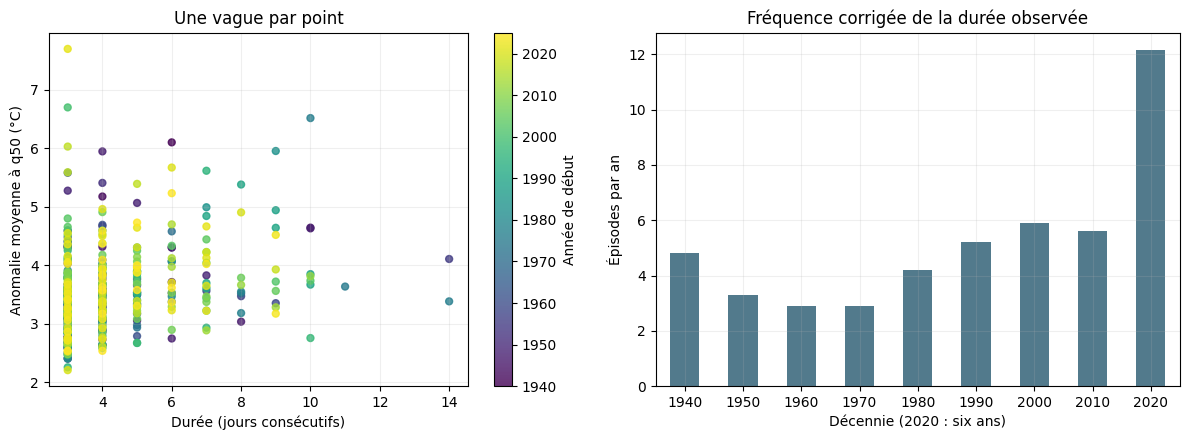

Nous trouvons **421 épisodes de trois jours ou plus**, contre 798 avec deux jours. La durée maximale est 14 jours et l'intensité moyenne 3.59 °C. Les événements longs ne sont pas forcément les plus intenses. La fréquence récente doit être lue relativement à la référence fixe 1940–2025, et les décennies comparées par année observée. Un seuil saisonnier commun montre un déplacement de la distribution ; ce comptage ne prouve pas, à lui seul, une cause.

In [5]:
def evenements(data, minimum=3):
    chaud = data["mean"]>data.q90
    rupture = chaud.ne(chaud.shift()) | data.valid_time.diff().ne(pd.Timedelta(days=1))
    groupes = rupture.cumsum()
    e = (data.assign(chaud=chaud, groupe=groupes, anomalie=data["mean"]-data.q50,
                     exces=data["mean"]-data.q90).loc[chaud].groupby("groupe")
         .agg(debut=("valid_time","first"), fin=("valid_time","last"), duree=("mean","size"),
              intensite=("anomalie","mean"), exces_q90=("exces","mean")))
    e=e[e.duree>=minimum].copy()
    e["annee"]=e.debut.dt.year
    return e
vagues = evenements(jours,3)
vagues2 = evenements(jours,2)
assert ((vagues.fin-vagues.debut).dt.days+1==vagues.duree).all()
assert len(vagues)==int(json.loads((RESULTATS/"heatwave_summary.json").read_text())["events_min3"]) if MODE=="rapide" else True
display(vagues.nlargest(5,"intensite").rename(columns={"duree":"Durée (jours)","intensite":"Intensité (°C)","exces_q90":"Excès q90 (°C)"}).round(3))
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
sc=axes[0].scatter(vagues.duree,vagues.intensite,c=vagues.annee,cmap="viridis",alpha=.8,s=25)
fig.colorbar(sc,ax=axes[0],label="Année de début")
axes[0].set(xlabel="Durée (jours consécutifs)",ylabel="Anomalie moyenne à q50 (°C)",title="Une vague par point")
annees=pd.Series(annual.year)
comptes=vagues.groupby(vagues.annee//10*10).size()
exposition=annees.groupby(annees//10*10).size()
(comptes/exposition).plot.bar(ax=axes[1],color="#527a8c",rot=0)
axes[1].set(xlabel="Décennie (2020 : six ans)",ylabel="Épisodes par an",title="Fréquence corrigée de la durée observée")
plt.tight_layout();plt.show()
display(Markdown(f"Nous trouvons **{len(vagues)} épisodes de trois jours ou plus**, contre {len(vagues2)} "
    f"avec deux jours. La durée maximale est {vagues.duree.max()} jours et l'intensité moyenne {vagues.intensite.mean():.2f} °C. "
    "Les événements longs ne sont pas forcément les plus intenses. La fréquence récente doit être lue "
    "relativement à la référence fixe 1940–2025, et les décennies comparées par année observée. "
    "Un seuil saisonnier commun montre un déplacement de la distribution ; ce comptage ne prouve pas, à lui seul, une cause."))

## 3. Partie 2 — Des extrêmes irréguliers et un signal de CO₂ faible

Nous traçons les maxima **et** minima annuels. La moyenne glissante centrée
sur 11 ans sert uniquement à lire le passé. Elle utilise des années voisines,
parfois futures par rapport à une date : ce n'est pas une entrée de prévision.

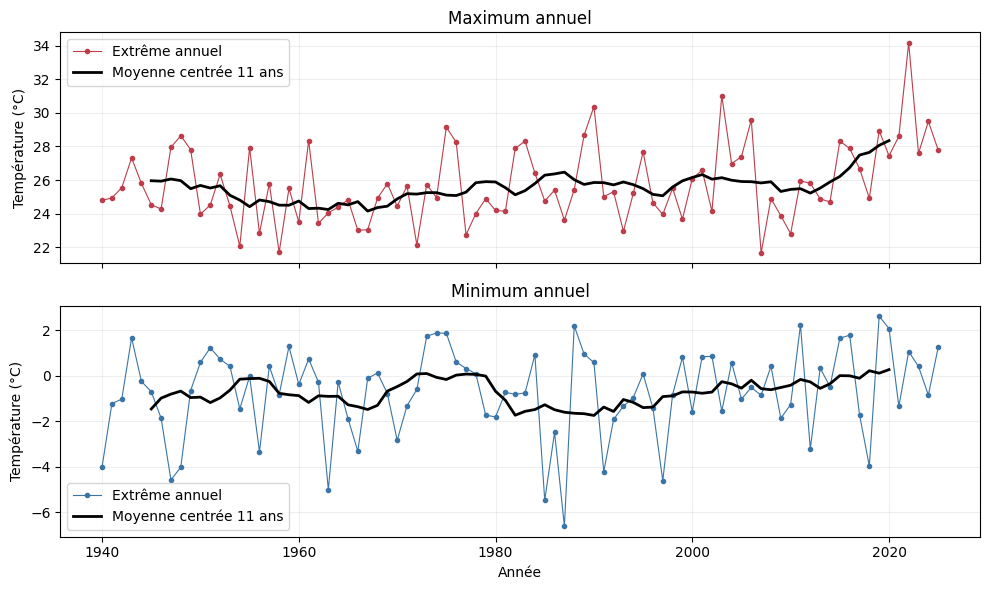

max         min      
            mean   std  mean   std
1940–1979  25.10  1.92 -0.72  1.79
1980–2025  26.33  2.43 -0.71  2.04

Le maximum varie entre 21.7 et 34.2 °C. La variabilité annuelle reste grande devant le déplacement des moyennes. Le minimum ne doit pas être obtenu en inversant arbitrairement la loi du maximum : nous l'ajustons et l'évaluons séparément.

In [6]:
fig, axes=plt.subplots(2,1,figsize=(10,6),sharex=True)
for ax,v,c in zip(axes,["max","min"],["#bd3d4b","#3b75a7"]):
    ax.plot(annual.year,annual[v],".-",lw=.8,color=c,label="Extrême annuel")
    ax.plot(annual.year,annual[v].rolling(11,center=True).mean(),color="black",lw=2,label="Moyenne centrée 11 ans")
    ax.set(ylabel="Température (°C)",title="Maximum annuel" if v=="max" else "Minimum annuel");ax.legend()
axes[-1].set_xlabel("Année");plt.tight_layout();plt.show()
description=annual.groupby(np.where(annual.year<1980,"1940–1979","1980–2025"))[["max","min"]].agg(["mean","std"])
display(description.round(2))
display(Markdown(f"Le maximum varie entre {annual['max'].min():.1f} et {annual['max'].max():.1f} °C. "
    "La variabilité annuelle reste grande devant le déplacement des moyennes. "
    "Le minimum ne doit pas être obtenu en inversant arbitrairement la loi du maximum : "
    "nous l'ajustons et l'évaluons séparément."))

In [7]:
correlations=[]
for periode,d in [("1940–2000",annual[annual.year<=2000]),("1940–2025",annual)]:
    for v in ["max","min"]:
        for nom,T in [("T",d[v]),("T lissée 5 ans",d[v].rolling(5,center=True).mean()),
                      ("T lissée 11 ans",d[v].rolling(11,center=True).mean()),("T lissée 21 ans",d[v].rolling(21,center=True).mean())]:
            for cn,C in [("CO₂",d.co2),("log(CO₂)",np.log(d.co2)),("√CO₂",np.sqrt(d.co2))]:
                correlations.append({"Période":periode,"Variable":v,"Transformation T":nom,"Transformation CO₂":cn,"r de Pearson":T.corr(C),"Paires":int(T.notna().sum())})
corr=pd.DataFrame(correlations)
display(corr.pivot_table(index=["Période","Variable","Transformation T"],columns="Transformation CO₂",values="r de Pearson").round(3))
display(Markdown("Le lissage augmente la corrélation en atténuant le bruit annuel, mais réduit aussi "
    "le nombre de degrés de liberté et crée une dépendance entre points. Cela ne rend pas prévisible "
    "le maximum d'une année particulière. Sur cette plage de CO₂, log(CO₂) et CO₂ restent proches. "
    "Une forte corrélation entre séries tendancielles ne démontre pas une causalité ni une bonne extrapolation."))

Transformation CO₂                     CO₂  log(CO₂)   √CO₂
Période   Variable Transformation T                        
1940–2000 max      T                 0.045     0.042  0.043
                   T lissée 11 ans   0.379     0.364  0.372
                   T lissée 21 ans   0.647     0.637  0.642
                   T lissée 5 ans    0.132     0.122  0.127
          min      T                -0.051    -0.046 -0.049
                   T lissée 11 ans  -0.313    -0.303 -0.308
                   T lissée 21 ans  -0.447    -0.434 -0.441
                   T lissée 5 ans   -0.197    -0.189 -0.193
1940–2025 max      T                 0.314     0.304  0.309
                   T lissée 11 ans   0.608     0.595  0.602
                   T lissée 21 ans   0.828     0.823  0.826
                   T lissée 5 ans    0.490     0.474  0.482
          min      T                 0.150     0.147  0.148
                   T lissée 11 ans   0.257     0.244  0.250
                   T lissée 21 ans   0.210     0.193  0.201
                   T lissée 5 ans    0.243     0.233  0.238

Le lissage augmente la corrélation en atténuant le bruit annuel, mais réduit aussi le nombre de degrés de liberté et crée une dépendance entre points. Cela ne rend pas prévisible le maximum d'une année particulière. Sur cette plage de CO₂, log(CO₂) et CO₂ restent proches. Une forte corrélation entre séries tendancielles ne démontre pas une causalité ni une bonne extrapolation.

## 4. Comparer des distributions sans utiliser les températures de test

| Bloc | Ajustement | Validation |
|---|---|---|
| F1 | 1940–1970 | 1971–1980 |
| F2 | 1940–1980 | 1981–1990 |
| F3 | 1940–1990 | 1991–2000 |

Les seuils, ancres, normalisations et distributions de paramètres sont
ajustés séparément sur chaque train. Les réseaux sont arrêtés sur la
validation de leur bloc. Les choix d'hyperparamètres utilisent ensuite ces
mêmes blocs : c'est une validation de sélection, avec un optimisme possible,
et non une validation imbriquée.

Après gel du choix, nous ajustons sur 1940–2000, produisons 2001–2025 et les
trois lignes de 2100, vérifions les contrôles du kit, puis calculons les
scores test. Pour les projections finales seulement, nous réajustons sur les
**86 années 1940–2025**. Le futur n'utilise que le CO₂.

Le choix commun minimise le CRPS global non arrondi de validation. Le
twCRPS est un diagnostic complémentaire. Un modèle non admissible est écarté
selon les contrôles sans températures test, avec repli dans l'ordre de
validation. Le filtre historique « écart <0,05 puis simplicité » n'est pas
repris. La règle de départage des équipes du benchmark est une autre règle.

### CRPS global et twCRPS : deux questions complémentaires

$$\mathrm{CRPS}(F,y)=\mathbb E|X-y|-\tfrac12\mathbb E|X-X'|,
\qquad X,X'\overset{iid}{\sim}F.$$

Le CRPS évalue toute la distribution. Nous utilisons exactement l'estimateur
empirique du kit, avec 10 000 membres et le dénominateur $M^2$. Il est en °C.
Le CRPS d'un mélange se calcule sur le mélange ; ce n'est pas la moyenne des
scores de ses composants.

$$\mathrm{twCRPS}_{\mathrm{haut}}=
\mathrm{CRPS}\!\left(\max(X,s),\max(y,s)\right),\quad s=q_{80}(T_{\rm train}).$$

Pour Tmin et sa queue froide, nous remplaçons `max` par `min` et utilisons
$s=q_{20}(T_{\rm train})$. Toutes les années participent, y compris les
non-événements qui pénalisent les fausses alertes. Le score de queue n'est
pas un simple poids choisi après avoir observé une année chaude. Il est
plus ciblé, sans être universellement supérieur au CRPS global.
[Définition des scores pondérés](https://scoringrules.readthedocs.io/en/latest/weighted_scores.html).

La couverture mesurée et la largeur des intervalles complètent les scores :
un intervalle nominal de 80 % ne contient pas automatiquement 80 % des années.

In [8]:
def crps_rows(samples, observations):
    """Estimateur empirique M², identique au kit, float64 et O(M log M)."""
    x = np.sort(np.asarray(samples, dtype=np.float64), axis=-1)
    y = np.asarray(observations, dtype=np.float64)
    n = x.shape[-1]
    w = (2*np.arange(1,n+1)-n-1)/n**2
    return np.abs(x-y[...,None]).mean(axis=-1)-np.sum(x*w,axis=-1)

def twcrps_rows(samples, observations, threshold, variable):
    h = np.maximum if variable == 'max' else np.minimum
    return crps_rows(h(samples,threshold),h(observations,threshold))

def torch_crps(samples, observations, alpha=0.95):
    """alpha fair + (1-alpha) empirical, moyenne sur le batch."""
    import torch
    m = samples.shape[-1]
    if m < 2: raise ValueError('Au moins deux membres pour le score fair')
    x = samples.sort(dim=-1).values
    w = 2*torch.arange(1,m+1,device=x.device,dtype=x.dtype)-m-1
    first = (x-observations[...,None]).abs().mean(dim=-1)
    spread = (x*w).sum(dim=-1)
    return (first - spread * (alpha/(m*(m-1))+(1-alpha)/(m*m))).mean()

## 5. Ce que chaque famille apporte

### Référence et forme de la tendance

$$T(C)=a+b\log C+\sigma Z,\quad Z\sim\mathcal N(0,1),\quad b\ge0.$$

L'OLS est ajustée sur le train ; si sa pente est négative, nous la remettons
à zéro et recalculons l'intercept. L'incertitude sur les paramètres est
ignorée dans cette référence. Une ablation remplace log(C) par C en gardant
le même bruit gaussien : elle isole la forme de la tendance. Le logarithme
est motivé par le forçage radiatif du CO₂, mais cela ne garantit pas une
relation exacte entre CO₂ et extrême local. Une faible différence historique
peut devenir grande en extrapolant jusqu'à 946 ppm.

### Bayes — contribution de Christian

Avec $x=\log C-\overline{\log C}_{\rm train}$,
$$T_i=a+b x_i+\sigma\varepsilon_i,\quad
p(a,b,\sigma^2)\propto\sigma^{-2}\mathbf1_{b\ge0}.$$

Pour tirer le posterior, nous simulons d'abord le modèle non contraint :
$$\sigma^2\sim\frac{\mathrm{RSS}}{\chi^2_{n-2}},\qquad
(a,b)\mid\sigma^2\sim\mathcal N(\hat\beta,\sigma^2(X^TX)^{-1}),$$
puis nous rejetons **conjointement** les triplets dont $b<0$.
Après rejet, la marginale de $\sigma^2$ est proportionnelle à sa densité
non contrainte multipliée par $P(b\ge0\mid\sigma^2,T)$ : elle n'est donc plus,
en général, l'inverse-χ² écrite ci-dessus. La prédiction ajoute un bruit
annuel complet : $T^{(j)}(C)=a_j+b_j x+\sigma_j Z_j$.
Nous comparons aussi une version avec $b=0$.

In [9]:
def bayes_fit(co2, y, slope=True):
    """Statistiques suffisantes de la loi normale et du prior 1/sigma², b>=0."""
    co2, y = np.asarray(co2), np.asarray(y)
    center = np.log(co2).mean()
    X = np.c_[np.ones(len(y)), np.log(co2) - center][:, :1 + int(slope)]
    V = np.linalg.inv(X.T @ X)
    beta = V @ X.T @ y
    return dict(center=center, beta=beta, V=V, rss=np.sum((y-X@beta)**2),
                df=len(y)-X.shape[1], slope=slope, n=len(y))

def bayes_parameters(state, n, rng):
    """Rejet JOINT : sigma et beta acceptés ensemble, sans écrêtage de b."""
    beta, V = np.asarray(state["beta"]), np.asarray(state["V"])
    accepted, scales, total, count = [], [], 0, 0
    while count < n:
        batch = max(2*(n-count), 1024)
        sigma = np.sqrt(state["rss"] / rng.chisquare(state["df"], batch))
        theta = beta + sigma[:, None] * rng.normal(size=(batch, len(beta))) @ np.linalg.cholesky(V).T
        keep = theta[:, 1] >= 0 if state["slope"] else np.ones(batch, dtype=bool)
        accepted.append(theta[keep]); scales.append(sigma[keep])
        count += int(keep.sum()); total += batch
        if total > 1000*n:
            raise RuntimeError("Taux de rejet bayésien excessif : aucun remplacement silencieux")
    theta, sigma = np.concatenate(accepted)[:n], np.concatenate(scales)[:n]
    return theta[:, 0], theta[:, 1] if state["slope"] else np.zeros(n), sigma

### Quantiles — contribution de Yazid

Pour $\tau=0,01,\ldots,0,99$, nous ajustons une droite en CO₂ brut centré et
réduit sur le train, en minimisant la perte pinball et une pénalisation de pente :
$$\frac1n\sum_i\rho_\tau(y_i-a_\tau-b_\tau x_i)+\alpha|b_\tau|,
\qquad \rho_\tau(u)=u(\tau-\mathbf1_{u<0}).$$

Les quantiles sont réordonnés à chaque CO₂, interpolés en probabilité, puis
prolongés linéairement de 0 à 1 % et de 99 à 100 %. Tirer $U\sim\mathcal U(0,1)$
et calculer $Q(U\mid C)$ fournit une loi. Cette construction impose des
queues bornées ; elle ne permet pas de déduire solidement un risque rarissime.
Les 99 quantiles ne sont pas 99 observations indépendantes. Le tri résout
l'ordre des quantiles, pas la calibration.

Le notebook initial ajustait 1940–2025 avant de scorer 2001–2025, avec des α
différents entre figures et score. Ici chaque train est séparé, et α est
choisi parmi 0, 0,01, 0,1 et 1 sur validation. L'extension aux minima est
ajoutée lors de l'intégration ; la section initiale de Yazid était vide.
[Documentation de QuantileRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.QuantileRegressor.html).

In [10]:
from sklearn.linear_model import QuantileRegressor

def quantile_fit(co2, y, alpha):
    """99 quantiles, CO2 brut centré/réduit sur le train pour pénaliser la pente."""
    center, scale = np.mean(co2), np.std(co2)
    X = ((np.asarray(co2)-center)/scale)[:, None]
    tau = np.arange(1, 100)/100
    fits = [QuantileRegressor(quantile=q, alpha=alpha, solver="highs").fit(X, y) for q in tau]
    return dict(center=center, scale=scale, alpha=alpha, tau=tau,
                intercept=[f.intercept_ for f in fits], slope=[f.coef_[0] for f in fits])

def quantile_sample(state, co2, uniforms):
    """Réarrangement monotone, interpolation et prolongements linéaires jusqu'à 0 et 1.

    Ce choix impose des queues bornées. Il ne valide pas le risque rarissime de 40°C.
    Aucune masse n'est ajoutée artificiellement aux quantiles 1% et 99%.
    """
    x = (np.asarray(co2)-state["center"])/state["scale"]
    raw = np.asarray(state["intercept"])[None, :] + x[:, None]*np.asarray(state["slope"])
    q = np.sort(raw, axis=1)
    knots = np.c_[2*q[:, 0]-q[:, 1], q, 2*q[:, -1]-q[:, -2]]
    levels = np.r_[0., np.asarray(state["tau"]), 1.]
    return np.stack([np.interp(u, levels, row) for row, u in zip(knots, uniforms)])

### GEV non stationnaire — contribution de Reda

$$F(t\mid C)=\exp\left[-\left(1+\xi\frac{t-\mu(C)}{\sigma}\right)^{-1/\xi}\right],
\quad 1+\xi(t-\mu)/\sigma>0,\quad \mu(C)=\beta_0+\beta_1\log(C/C_0).$$

Les quatre paramètres sont estimés ensemble par vraisemblance en PyTorch,
puis 500 rééchantillonnages de paires propagent une incertitude de paramètres.
Cette méthode diffère d'une GEV ajustée aux résidus d'une OLS déjà fixée.
Le code ci-dessous centre le logarithme sur le train, ce qui change seulement
le paramétrage de l'intercept. Il refuse les pas sortant du support.

Nous conservons le choix de Reda $\beta_1\ge0$, $\xi\in[-0,5;-0,01]$.
Une forme négative donne une borne supérieure **dans ce modèle** ; le
théorème des extrêmes ne prouve ni ce signe ni une borne physique universelle.
Les maxima climatiques sont dépendants et non stationnaires : le recours à
la GEV reste une approximation. Estimer une loi classique avec PyTorch ne
suffit pas à constituer l'étude d'une méthode neuronale récente.
[GEV avec covariable CO₂ en climatologie](https://ascmo.copernicus.org/articles/9/45/2023/).

In [11]:
def gev_fit(co2, y, B=500, steps=3000, seed=0, device="cpu"):
    """GEV non stationnaire de Reda, avec contrôle explicite du support.

    L'optimisation vectorise les B réplications. Une mise à jour qui quitte le
    support est refusée pour la réplication concernée : les données impossibles
    ne reçoivent jamais une vraisemblance obtenue en écrêtant z.
    """
    torch.set_num_threads(1)
    x = np.log(np.asarray(co2))
    center = x.mean()
    x = torch.tensor(x-center, dtype=torch.float64, device=device)
    t = torch.tensor(np.asarray(y), dtype=torch.float64, device=device)
    gen = torch.Generator(device=device).manual_seed(seed)
    idx = torch.randint(len(t), (B, len(t)), generator=gen, device=device)
    idx[0] = torch.arange(len(t), device=device)
    xb, tb = x[idx], t[idx]
    theta = torch.tensor([t.mean().item(), 0., t.std().log().item(), -.1],
                         dtype=torch.float64, device=device).repeat(B, 1).requires_grad_()
    opt = torch.optim.Adam([theta], lr=.02)
    refused = 0
    for _ in range(steps):
        b0, b1, log_s, xi = theta.T[:, :, None]
        z = 1 + xi*(tb-b0-b1*xb)/log_s.exp()
        assert bool((z > 0).all()), "État GEV hors support avant optimisation"
        loss = (log_s+(1+1/xi)*z.log()+z.pow(-1/xi)).sum()
        if not torch.isfinite(loss):
            raise FloatingPointError("Vraisemblance GEV non finie")
        before = theta.detach().clone()
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            theta[:, 1].clamp_(min=0)
            theta[:, 3].clamp_(-.5, -.01)
            b0, b1, log_s, xi = theta.T[:, :, None]
            support = 1+xi*(tb-b0-b1*xb)/log_s.exp()
            invalid = (~torch.isfinite(support).all(1)) | (support.min(1).values <= 0) | (~torch.isfinite(theta).all(1))
            refused += int(invalid.sum())
            theta[invalid] = before[invalid]
            # Effacer l'élan des seules réplications refusées évite de répéter
            # mécaniquement la même sortie du support au pas suivant.
            for key in ("exp_avg", "exp_avg_sq"):
                opt.state[theta][key][invalid] = 0
    with torch.no_grad():
        b0, b1, log_s, xi = theta.T[:, :, None]
        z = 1+xi*(tb-b0-b1*xb)/log_s.exp()
    return dict(theta=theta.detach().cpu().numpy(), center=center, B=B, steps=steps,
                rejected_updates=refused, min_training_support=float(z.min()),
                device=device, seed=seed, shape_constraint=[-.5, -.01])

### Débruiteur distributionnel — contribution d'Elias

Pour conserver un modèle sobre, le CO₂ détermine une ancre $m(C)$ et le réseau
apprend la forme des résidus standardisés $z=(T-m(C))/s$. Nous supposons cette
loi résiduelle stable, ce qui doit être reconnu comme une limite en 2100.

À l'entraînement, $t\sim\mathcal U(0,1)$, $\epsilon\sim\mathcal N(0,1)$ et
$$u_t=(1-t)z+t\epsilon,\qquad \hat z_m=g_\phi(u_t,t,\eta_m),
\quad\eta_m\overset{iid}{\sim}\mathcal N(0,1).$$
Les 32 membres d'un exemple partagent $u_t,t$, avec des latents indépendants.
Le petit MLP a deux couches de 32 neurones SiLU et 1 217 paramètres.
Il minimise un score almost fair :
$$L=\frac1M\sum_m|\hat T_m-T|
-\frac12\left[\frac{0,95}{M(M-1)}+\frac{0,05}{M^2}\right]
  \sum_{m\ne\ell}|\hat T_m-\hat T_\ell|.$$

À l'inférence, **t=1**, donc $u=\epsilon$ ne contient aucune température
future ; le réseau génère un résidu en un passage. Le bruit de corruption
d'apprentissage, le latent de génération et l'incertitude de l'ancre ont des
rôles distincts. C0 utilise seulement l'extrémité t=1. D2 ajoute
$\lambda_{\rm tail}=0,5$ fois le score de queue. D3 ajoute à D1 une ancre
bootstrap par blocs de trois ans ; D4 fait la même chose avec D2.

Les trois réseaux entraînés avec des graines différentes sont mélangés.
Leur dispersion ne constitue pas un posterior sur les poids. Le débruitage
s'inspire de [Park et al. (2026)](https://arxiv.org/abs/2609.38632) ; le score
almost fair suit [Lang et al., AIFS-CRPS](https://arxiv.org/html/2412.15832v1).
L'adaptation scalaire ne reprend pas leurs résultats de prévision météo globale.
Même 1 217 paramètres restent nombreux devant 61 observations annuelles :
l'arrêt précoce et le mélange des graines limitent les instabilités, sans
constituer une garantie de généralisation.

In [12]:
from typing import Sequence
from torch import nn
from sma.models.ddpm import scalar_mlp

class ScalarDDM(nn.Module):
    def __init__(self, hidden_dims: Sequence[int] = (32, 32), direct: bool = False):
        super().__init__()
        self.hidden_dims = tuple(int(v) for v in hidden_dims)
        self.direct = bool(direct)
        self.network = scalar_mlp(3, self.hidden_dims)

    def forward(self, u: torch.Tensor, t: torch.Tensor, latent: torch.Tensor) -> torch.Tensor:
        return self.network(torch.stack((u, t, latent), dim=-1)).squeeze(-1)

    def ensemble_inputs(self, z: torch.Tensor, members: int, generator: torch.Generator
                        ) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        if z.ndim != 1 or members < 2:
            raise ValueError("Expected z of shape (B,) and at least two ensemble members")
        count = z.shape[0]
        if self.direct:
            u = torch.zeros_like(z)
            t = torch.ones_like(z)
        else:
            t = torch.rand(count, device=z.device, generator=generator)
            corruption = torch.randn(count, device=z.device, generator=generator)
            u = (1.0 - t) * z + t * corruption
        latent = torch.randn(count, members, device=z.device, generator=generator)
        return u[:, None].expand(-1, members), t[:, None].expand(-1, members), latent

    def training_ensemble(self, z: torch.Tensor, members: int,
                          generator: torch.Generator) -> torch.Tensor:
        return self(*self.ensemble_inputs(z, members, generator))

    @torch.no_grad()
    def sample(self, n: int, generator: torch.Generator, batch_size: int = 4096) -> torch.Tensor:
        if n < 0 or batch_size < 1:
            raise ValueError("n must be nonnegative and batch_size positive")
        device = next(self.parameters()).device
        chunks = []
        for start in range(0, n, batch_size):
            count = min(batch_size, n - start)
            u = (torch.zeros(count, device=device) if self.direct else
                 torch.randn(count, device=device, generator=generator))
            latent = torch.randn(count, device=device, generator=generator)
            chunks.append(self(u, torch.ones(count, device=device), latent))
        return torch.cat(chunks) if chunks else torch.empty(0, device=device)

In [13]:
def entrainer_exemple(z, mu, observations, echelle, seuil, variable, pas=250, poids_queue=0.):
    """Boucle essentielle ; la matrice utilise aussi arrêt et checkpoints."""
    torch.manual_seed(12)
    reseau=ScalarDDM((32,32))
    optimiseur=torch.optim.AdamW(reseau.parameters(),lr=.001,weight_decay=.0001)
    generateur=torch.Generator().manual_seed(100015)
    z,mu,observations=[torch.tensor(np.asarray(v),dtype=torch.float32) for v in (z,mu,observations)]
    pertes=[]
    for _ in range(pas):
        i=torch.randint(len(z),(64,),generator=generateur)
        pred=mu[i,None]+echelle*reseau.training_ensemble(z[i],32,generateur)
        perte=torch_crps(pred,observations[i],alpha=.95)
        if poids_queue:
            h=torch.clamp_min if variable=="max" else torch.clamp_max
            perte=perte+poids_queue*torch_crps(h(pred,seuil),h(observations[i],seuil),alpha=.95)
        optimiseur.zero_grad();perte.backward()
        torch.nn.utils.clip_grad_norm_(reseau.parameters(),1.)
        optimiseur.step();pertes.append(float(perte.detach()))
    return reseau,pertes

# Petit entraînement pédagogique réellement exécuté, sur 1940–2000 seulement.
# Il illustre la boucle ; il ne remplace pas les modèles du tableau comparatif.
etat_demo=json.loads((MODELES/"historique/max/suite.json").read_text())
a=etat_demo["anchor"]
mu=a["a"]+a["b"]*np.log(train.co2.to_numpy())
demo,pertes=entrainer_exemple(a["z"],mu,train["max"],a["sigma"],etat_demo["threshold"],"max")
assert np.isfinite(pertes).all()
print(sum(p.numel() for p in demo.parameters()),"paramètres ;",len(pertes),"pas exécutés sur le train")

1217 paramètres ; 250 pas exécutés sur le train


### H0 et H1 — deux combinaisons testées lors de l'intégration

**H0, mélange de lois complètes :**
$$F_{\rm mix}=wF_{\rm Bayes}+(1-w)F_{\rm DDM},
\qquad w\in\{0;0,25;0,5;0,75;1\}.$$
La composante D1 ou D3 est choisie sur validation. Pour chaque membre, nous
choisissons une distribution, puis une température dans cette distribution.
Nous ne faisons pas la moyenne numérique de deux températures, et n'ajoutons
pas une variance après ce mélange. Les extrémités sont les contrôles seuls.
[Mélanges de distributions prédictives, Gneiting et Ranjan](https://arxiv.org/abs/1106.1638).

**H1, ancre bayésienne et forme résiduelle neuronale :**
$$T^{(j)}(C)=a_j+b_j(\log C-x_0)+\sigma_j Z_{\phi,j},\quad
Z_\phi=\frac{g_\phi(\epsilon,1,\eta)-\mu_\phi}{s_\phi}.$$
Les moments $(\mu_\phi,s_\phi)$ sont estimés avec 100 000 simulations fixées
pour chaque train. Nous utilisons la sortie résiduelle D1 avant son ancre,
sans ancre bootstrap et sans second bruit gaussien. La dépendance entre
$a_j,b_j,\sigma_j$ est conservée.

H1 est une **combinaison modulaire approximative** : le posterior des
paramètres a été calculé sous vraisemblance normale. Changer ensuite
l'innovation ne produit pas le posterior exact d'une vraisemblance neuronale.
Les expériences sont un test local de cette adaptation, pas une validation
théorique ni une quantification bayésienne des poids du réseau.

In [14]:
def mixture_sample(bayes, diffusion, weight):
    """Échantillonnage stratifié d'un mélange de LOIS, sans moyenner leurs valeurs."""
    if weight == 1:
        return bayes.copy()
    if weight == 0:
        return diffusion.copy()
    n = bayes.shape[1]
    nb = int(round(n*weight))
    return np.concatenate([bayes[:, :nb], diffusion[:, nb:]], axis=1)

def tirer_d3_visible(suite, co2, n=10000, seed=8200):
    from sma.final_models import neural_sample
    rng=np.random.default_rng(seed)
    z=neural_sample(suite,"D1",n,rng,RACINE)
    # L'ancre incertaine est tirée séparément des fluctuations annuelles.
    boot=suite["bootstrap"]
    i=rng.integers(len(boot["a"]),size=n)
    return (np.asarray(boot["a"])[i]+np.log(np.asarray(co2))[:,None]*np.asarray(boot["b"])[i]
            +suite["anchor"]["sigma"]*z)

def combinaison_h1_visible(suite, co2, n=10000, seed=8200):
    # Même convention de localisation et d'échelle que le moteur d'expériences.
    from sma.final_models import neural_sample
    rng=np.random.default_rng(seed)
    a,b,sigma=bayes_parameters(suite["bayes"],n,rng)
    z=neural_sample(suite,"D1",n,rng,RACINE)
    moments=suite["h1_moments"]
    z=(z-moments["mean"])/moments["std"]
    x=np.log(np.asarray(co2))[:,None]-suite["bayes"]["center"]
    return a+b*x+sigma*z

assert np.allclose(combinaison_h1_visible(etat_demo,[400]),
    predictive_sample(etat_demo,"H1",[400],root=RACINE))
assert np.allclose(tirer_d3_visible(etat_demo,[400]),
    predictive_sample(etat_demo,"D3",[400],root=RACINE))

## 6. Résultats comparatifs et décision

La grande matrice est dans le script versionné `run_final_team.py`. Elle
conserve toutes les variantes, y compris celles qui perdent. Les tableaux
suivants viennent des expériences terminées, avec 30 années de validation
et 25 années de test, toujours 10 000 membres par année.

Les scores des différentes familles sont comparables ; leurs différences
ne sont pas toutes des ablations isolées. En particulier Bayes contre D3
change à la fois la loi des paramètres et celle des fluctuations.

In [15]:
validation=pd.read_csv(RESULTATS/"validation.csv")
test_scores=pd.read_csv(RESULTATS/"test.csv")
controles=pd.read_csv(RESULTATS/"controles_kit.csv")
for v in ["max","min"]:
    display(Markdown("### "+("Maxima" if v=="max" else "Minima")+" : validation"))
    sub=validation[(validation.variable==v)&~validation.model.str.startswith("H0_")].sort_values("crps")
    tableau(sub[["model","crps","twcrps","coverage80","width80","bias"]])
display(Markdown(f"Le minimum de CRPS conduit à **{choix['selected']['max']} pour Tmax et {choix['selected']['min']} pour Tmin**. "
    "Les contrôles sont appliqués après ce classement, sans consulter les températures test. "
    "Dans l'exécution remise, aucune procédure de repli n'a été nécessaire."))

### Maxima : validation

,Modèle,CRPS (°C),twCRPS (°C),Couverture 80 %,Largeur 80 % (°C),Biais (°C)
5,D3,1.1142,0.3787,0.8333,5.7010,0.1116
6,D4,1.1147,0.3781,0.8667,5.7247,0.0976
3,D1,1.1231,0.3867,0.8000,5.5374,-0.0888
4,D2,1.1241,0.3860,0.8000,5.5662,-0.1027
17,QR_1,1.1369,0.3995,0.7333,5.1658,-0.4039
16,QR_0.1,1.1411,0.3996,0.7667,5.2776,-0.4769
1,Bayes0,1.1450,0.4113,0.7667,5.0903,-0.3958
2,C0,1.1461,0.4069,0.7000,5.1181,-0.2194
13,H1,1.1610,0.3998,0.7333,5.1844,0.0735
7,GEV,1.1653,0.4171,0.7000,4.7952,-0.2640


### Minima : validation

,Modèle,CRPS (°C),twCRPS (°C),Couverture 80 %,Largeur 80 % (°C),Biais (°C)
23,D1,1.1681,0.4094,0.7667,5.3822,0.2709
25,D3,1.1737,0.4069,0.8667,5.6046,0.4729
24,D2,1.1764,0.4114,0.7667,5.3005,0.3263
26,D4,1.1851,0.4094,0.8667,5.5133,0.5284
21,Bayes0,1.1943,0.4131,0.7333,4.8999,0.0213
36,QR_1,1.1957,0.4137,0.7333,4.9650,0.0262
35,QR_0.1,1.1958,0.4137,0.7333,4.9650,0.0264
22,C0,1.2010,0.4192,0.7333,4.6201,0.3013
20,Bayes,1.2166,0.4276,0.8333,5.0894,0.7239
38,R_log,1.2195,0.4290,0.7333,4.8207,0.3703


Le minimum de CRPS conduit à **D3 pour Tmax et D1 pour Tmin**. Les contrôles sont appliqués après ce classement, sans consulter les températures test. Dans l'exécution remise, aucune procédure de repli n'a été nécessaire.

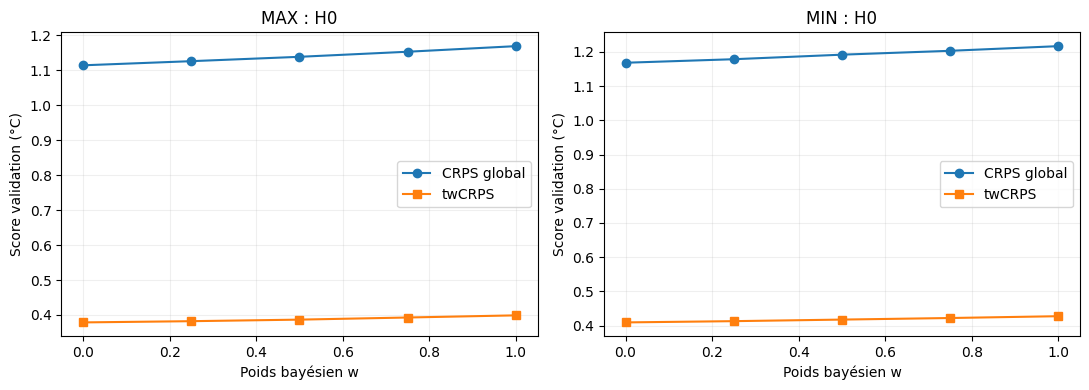

,Variable,Modèle,CRPS (°C),twCRPS (°C),Couverture 80 %,Largeur 80 % (°C)
0,max,Bayes,1.1690,0.3989,0.7333,5.2412
3,max,D1,1.1231,0.3867,0.8000,5.5374
5,max,D3,1.1142,0.3787,0.8333,5.7010
8,max,H0_D3_0,1.1142,0.3787,0.8333,5.7010
13,max,H1,1.1610,0.3998,0.7333,5.1844
20,min,Bayes,1.2166,0.4276,0.8333,5.0894
23,min,D1,1.1681,0.4094,0.7667,5.3822
25,min,D3,1.1737,0.4069,0.8667,5.6046
27,min,H0_D1_0,1.1681,0.4094,0.7667,5.3822
32,min,H1,1.2408,0.4231,0.8333,5.0703


Les poids retenus sont `{'max': 'H0_D3_0', 'min': 'H0_D1_0'}`. Dans le rendu remis, **w=0 pour les deux variables** : le mélange n'apporte donc pas de gain sur validation. H1 ne dépasse pas D1/D3 sur ces blocs. Il n'y a aucune raison de forcer une combinaison pour annoncer une amélioration.

training_seconds  additional_seconds
phase      model                                      
F1         C0               307.52                0.08
           D1               185.18                0.06
           D2               228.97                0.06
F2         C0               204.74                0.07
           D1               289.93                0.06
           D2               366.00                0.07
F3         C0               200.41                0.09
           D1               190.03                0.07
           D2               194.74                0.07
complet    C0               154.61               85.43
           D1                66.66               27.48
           D2                73.08               73.21
historique C0               138.54                0.07
           D1                68.37                0.07
           D2                70.28                0.07

Temps en secondes : coût d'entraînement attribué et coût supplémentaire de l'exécution.


In [16]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,v in zip(axes,["max","min"]):
    sub=validation[(validation.variable==v)&validation.model.str.startswith("H0_")].copy()
    sub["w"]=sub.model.str.split("_").str[-1].astype(float);sub=sub.sort_values("w")
    ax.plot(sub.w,sub.crps,"o-",label="CRPS global")
    ax.plot(sub.w,sub.twcrps,"s-",label="twCRPS")
    ax.set(xlabel="Poids bayésien w",ylabel="Score validation (°C)",title=v.upper()+" : H0")
    ax.legend()
plt.tight_layout();plt.show()
ablation=validation[validation.model.isin(["Bayes","D1","D3","H1",*choix["h0"].values()])]
tableau(ablation[["variable","model","crps","twcrps","coverage80","width80"]])
display(Markdown(f"Les poids retenus sont `{choix['h0']}`. Dans le rendu remis, **w=0 pour les deux variables** : "
    "le mélange n'apporte donc pas de gain sur validation. H1 ne dépasse pas D1/D3 sur ces blocs. "
    "Il n'y a aucune raison de forcer une combinaison pour annoncer une amélioration."))
lignes_couts=[]
for fichier in MODELES.rglob("seed*.json"):
    c=json.loads(fichier.read_text())
    lignes_couts.append({**c["identity"],"training_seconds":c["training_seconds"],
                         "additional_seconds":c["additional_seconds"]})
couts=pd.DataFrame(lignes_couts)
display(couts.groupby(["phase","model"])[["training_seconds","additional_seconds"]].sum().round(2))
print("Temps en secondes : coût d'entraînement attribué et coût supplémentaire de l'exécution.")

### Le test déjà connu : un résultat différent de la validation

Nous ne changeons pas le choix après avoir vu ce tableau. Dans le rendu
remis, Bayes atteint environ 1,580 °C de CRPS Tmax et D3 environ 1,650 °C.
D3 obtient en revanche un twCRPS Tmax plus faible (environ 0,681 contre 0,693).
Les deux scores répondent à des questions différentes. La pondération de
queue est utile pour les probabilités élevées observables ; elle ne valide
pas, à elle seule, la probabilité de 40 °C en 2100.

La GEV adaptée obtient environ 1,680 °C. Le 1,66 °C annoncé dans le notebook
de Reda reste un résultat historique distinct : le centrage numérique, le
contrôle du support et les tirages sont harmonisés ici. Le score initial
de Yazid sur 2001–2025 était dans l'échantillon et n'est pas repris comme
résultat hors échantillon.

Au seuil commun du train, le test contient 12 maxima au-dessus de q80 et
seulement deux minima sous q20. Le score de queue froide est donc surtout
informé par très peu d'événements et les fausses alertes ; son classement
ne suffit pas à conclure sur les gels extrêmes.

### MAX : test exploratoire

,Modèle,CRPS (°C),twCRPS (°C),Couverture 80 %,Largeur 80 % (°C),Biais (°C)
2,Bayes,1.5802,0.6932,0.68,5.1854,-1.0413
9,H1,1.5951,0.6891,0.72,5.2177,-1.0559
7,D3,1.6500,0.6814,0.76,6.1603,-1.2878
8,D4,1.6553,0.6845,0.76,6.1128,-1.3153
14,GEV,1.6798,0.7150,0.64,4.8004,-1.2614
1,R_linear,1.6954,0.7272,0.64,5.0011,-1.3919
5,D1,1.7013,0.6932,0.76,6.0182,-1.4319
0,R_log,1.7077,0.7296,0.64,5.0018,-1.4232
6,D2,1.7078,0.6970,0.72,5.9688,-1.4594
4,C0,1.7578,0.7122,0.64,5.0359,-1.4210


Seuil fixé sur 1940–2000 : 27.317 °C ; événements observés : 12 sur 25 ans


### MIN : test exploratoire

,Modèle,CRPS (°C),twCRPS (°C),Couverture 80 %,Largeur 80 % (°C),Biais (°C)
29,H1,0.9693,0.1406,0.88,5.2902,-0.4502
22,Bayes,0.9800,0.1381,0.84,5.2174,-0.4312
28,D4,0.9804,0.1502,0.92,5.8918,-0.4518
27,D3,0.9893,0.1527,0.88,5.8289,-0.5391
26,D2,1.0197,0.1614,0.84,5.8010,-0.7217
33,QR_1,1.0302,0.1537,0.80,5.3315,-0.8566
32,QR_0.1,1.0302,0.1537,0.80,5.3315,-0.8566
24,C0,1.0302,0.1510,0.72,4.9604,-0.8584
25,D1,1.0361,0.1650,0.84,5.7674,-0.8090
31,QR_0.01,1.0591,0.1553,0.76,5.5740,-0.9982


Seuil fixé sur 1940–2000 : -1.916 °C ; événements observés : 2 sur 25 ans


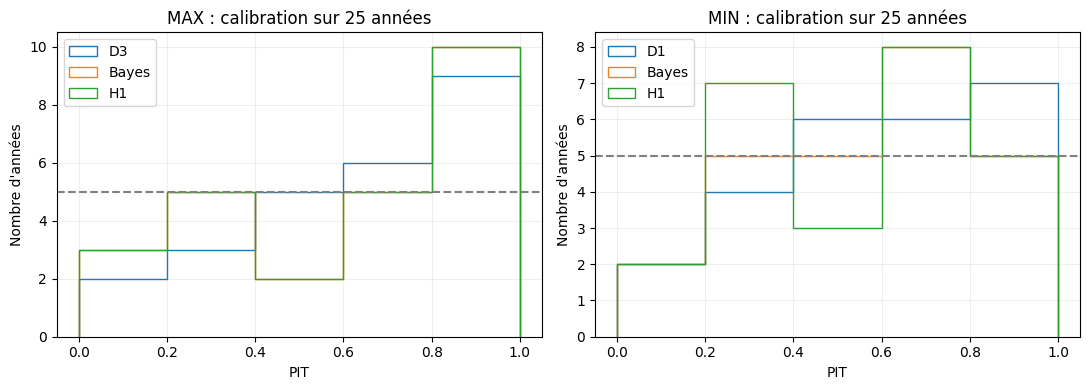

In [17]:
par_annee=pd.read_csv(RESULTATS/"test_par_annee.csv")
for v in ["max","min"]:
    display(Markdown("### "+v.upper()+" : test exploratoire"))
    sub=test_scores[(test_scores.variable==v)&~test_scores.model.str.startswith("H0_")].sort_values("crps")
    tableau(sub[["model","crps","twcrps","coverage80","width80","bias"]])
    evenements_test=par_annee[(par_annee.variable==v)&(par_annee.model==choix["selected"][v])]
    print("Seuil fixé sur 1940–2000 :",round(evenements_test.threshold_C.iloc[0],3),"°C ; événements observés :",int(evenements_test.event_observed.sum()),"sur 25 ans")
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,v in zip(axes,["max","min"]):
    for m in list(dict.fromkeys([choix["selected"][v],"Bayes","H1"])):
        s=par_annee[(par_annee.variable==v)&(par_annee.model==m)]
        ax.hist(s.pit,bins=np.linspace(0,1,6),histtype="step",label=m)
    ax.axhline(5,color="grey",ls="--");ax.set(xlabel="PIT",ylabel="Nombre d'années",title=v.upper()+" : calibration sur 25 années");ax.legend()
plt.tight_layout();plt.show()

### Distinguer les incertitudes

La variabilité météorologique d'une année reste présente même si les
paramètres sont connus. L'incertitude des paramètres augmente en extrapolation,
et les hypothèses de modèle ajoutent une incertitude que nos intervalles ne
couvrent pas entièrement. Les trois graines du réseau ne constituent pas un
échantillon de posterior. Enfin, les 10 000 membres réduisent le bruit de
simulation, sans ajouter d'années observées.

Les intervalles ci-dessous sont des bootstrap **appariés par blocs de trois
ans** des différences de CRPS test. Ils restent fragiles avec 25 années,
ne corrigent pas la consultation préalable du test et ne prédisent pas la
qualité en 2100. Les intervalles binomiaux de couverture sont indicatifs,
car l'indépendance des années n'est pas démontrée.

Dans l'exécution remise, D3 et D4 ne diffèrent que d'environ 0,0005 °C de
CRPS de validation. Ce rang numérique ne démontre pas une supériorité de D3.
Les cinq répétitions de tirages sur le test donnent des écarts-types de
CRPS d'environ 0,003 à 0,010 °C selon la méthode. Nous conservons le choix
déterminé à l'avance, en reconnaissant la faible portée de ces petits écarts.

In [18]:
if MODE=="rapide":
    display(pd.read_csv(RESULTATS/"incertitude_ecarts_crps.csv").round(4))
    display(pd.read_csv(RESULTATS/"incertitude_couvertures.csv").round(4))
    mc=pd.read_csv(RESULTATS/"sensibilite_monte_carlo.csv")
    display(mc.groupby(["variable","model"])[["crps","twcrps"]].agg(["mean","std"]).round(4))
else:
    # Bootstrap exécuté aussi pour les résultats nouvellement entraînés.
    lignes=[]
    for v,m in choix["selected"].items():
        p=par_annee[(par_annee.variable==v)&par_annee.model.isin([m,"Bayes"])].pivot(index="year",columns="model",values="crps")
        d=(p[m]-p["Bayes"]).to_numpy();rng=np.random.default_rng(74102)
        ix=((rng.integers(len(d),size=(4000,9,1))+np.arange(3))%len(d)).reshape(4000,-1)[:,:len(d)]
        ci=np.quantile(d[ix].mean(1),[.025,.975])
        lignes.append({"Variable":v,"Différence à Bayes (°C)":d.mean(),"Borne 2,5 % (°C)":ci[0],"Borne 97,5 % (°C)":ci[1]})
    display(pd.DataFrame(lignes).round(4))

,variable,model,reference,difference_C,lower95_C,upper95_C,n_years,blocks,replicates
0,max,D3,Bayes,0.0698,-0.0218,0.1483,25,3,4000
1,max,D3,R_log,-0.0577,-0.1206,0.0006,25,3,4000
2,max,H1,Bayes,0.0149,-0.0092,0.0366,25,3,4000
3,min,D1,Bayes,0.0560,0.0137,0.0933,25,3,4000


,variable,model,hits,n,coverage,lower95,upper95
0,max,D3,19,25,0.76,0.5487,0.9064
1,max,Bayes,17,25,0.68,0.4650,0.8505
2,min,D1,21,25,0.84,0.6392,0.9546
3,min,Bayes,21,25,0.84,0.6392,0.9546


crps          twcrps        
                  mean     std    mean     std
variable model                                
max      Bayes  1.5739  0.0047  0.6926  0.0016
         D1     1.6969  0.0101  0.6959  0.0026
         D3     1.6448  0.0088  0.6834  0.0024
         H1     1.5868  0.0034  0.6881  0.0010
min      Bayes  0.9808  0.0018  0.1392  0.0009
         D1     1.0390  0.0049  0.1661  0.0008
         D3     0.9926  0.0028  0.1539  0.0008
         H1     0.9687  0.0015  0.1398  0.0004

### Contrôles et échecs conservés

Le kit impose les formes (25,10 000) pour le test, (3,10 000) pour 2100,
l'ordre SSP1-2.6, SSP2-4.5, SSP5-8.5 et trois contrôles : médianes croissantes
à 0,1 °C près ; largeur 80 % SSP5 au moins égale à 95 % de la largeur moyenne
test ; tous les membres dans [0;50] °C pour Tmax et [−30;20] °C pour Tmin.
Nous les appliquons aux tirages bruts, sans clipping.
Réussir ces contrôles sur un ensemble fini ne prouve pas que la loi entière
est physiquement bornée ni qu'elle sera juste en 2100.

Le **DDPM classique** étudié par Elias est éliminé : minimum simulé
−1 933,216 °C, 19 152 tirages Tmin hors bornes et CRPS Tmin 2,620 °C.
Son bon score de validation ne suffit pas. Le terme inverse du calendrier
peut amplifier une erreur au dernier niveau de bruit ; ce diagnostic
n'autorise pas à supprimer les valeurs défavorables. D1 génère directement
une sortie débruitée et n'utilise pas cette chaîne inverse.

Dans les adaptations communes, les QR peu pénalisées et le bootstrap Tmin
à pente libre de Reda peuvent perdre la monotonie ; QR_0.01 Tmin sort aussi
des bornes. Ces méthodes restent visibles. La pente positive du benchmark
est un garde-fou de modèle, pas l'affirmation que chaque année plus riche
en CO₂ doit être plus chaude que l'année précédente.

In [19]:
from sma.benchmark_adapter import check_predictions
import importlib.util
c2100=future.loc[future.valid_time.dt.year==2100,list(SCENARIOS)].to_numpy().ravel()
previsions={}
for v in ["max","min"]:
    suite=json.loads((MODELES/f"historique/{v}/suite.json").read_text())
    seed=8200+1000*(v=="min")
    previsions["test_"+v]=predictive_sample(suite,choix["selected"][v],inputs.co2,root=RACINE,seed=seed)
    previsions["proj_"+v]=predictive_sample(suite,choix["selected"][v],c2100,root=RACINE,seed=seed)
verification=check_predictions(previsions)
assert verification["admissible"],verification
spec=importlib.util.spec_from_file_location("kit_original",RACINE/"rendu_final/sources/kit.py")
kit=importlib.util.module_from_spec(spec);spec.loader.exec_module(kit);kit.DATA=DONNEES
score_recalcule=kit.benchmark(**previsions)
for i,v in enumerate(["max","min"]):
    attendu=test_scores[(test_scores.variable==v)&(test_scores.model==choix["selected"][v])].crps.iloc[0]
    assert abs(score_recalcule[i]-attendu)<2e-5
tableau(controles[["model","variable","monotonic","width_ok","bounds_ok","outside_bounds"]])

Tests de cohérence : OK
SCORE FINAL (CRPS du max, 2001-2025) : 1.65 °C   (référence à battre : 1.70)
Départage   (CRPS du min, 2001-2025) : 1.04 °C   (référence : 1.06)


,Modèle,Variable,monotonic,width_ok,bounds_ok,outside_bounds
0,R_log,max,True,True,True,0
1,R_linear,max,True,True,True,0
2,Bayes,max,True,True,True,0
3,Bayes0,max,True,True,True,0
4,C0,max,True,True,True,0
5,D1,max,True,True,True,0
6,D2,max,True,True,True,0
7,D3,max,True,True,True,0
8,D4,max,True,True,True,0
9,H1,max,True,True,True,0


## 7. Projeter 2026–2100 : un calcul conditionnel, pas une validation future

Les familles retenues sont réajustées sur 1940–2025. Nous présentons D3 pour
Tmax et D1 pour Tmin dans l'exécution remise. Les trajectoires ci-dessous
sont des réalisations annuelles, pas une prédiction du jour le plus chaud.
Nous représentons la médiane et l'intervalle central nominal de 90 %.

Pour chaque trajectoire D3, nous tirons une ancre bootstrap commune aux
75 ans ; les innovations annuelles sont ensuite indépendantes conditionnellement
à cette ancre. Pour Bayes et H1, le triplet de paramètres est également
partagé par trajectoire. Pour H0, la composante est choisie une fois par
trajectoire. Des bruits communs peuvent servir aux comparaisons de **marges**,
mais ne doivent pas être confondus avec cette hypothèse de dépendance temporelle.

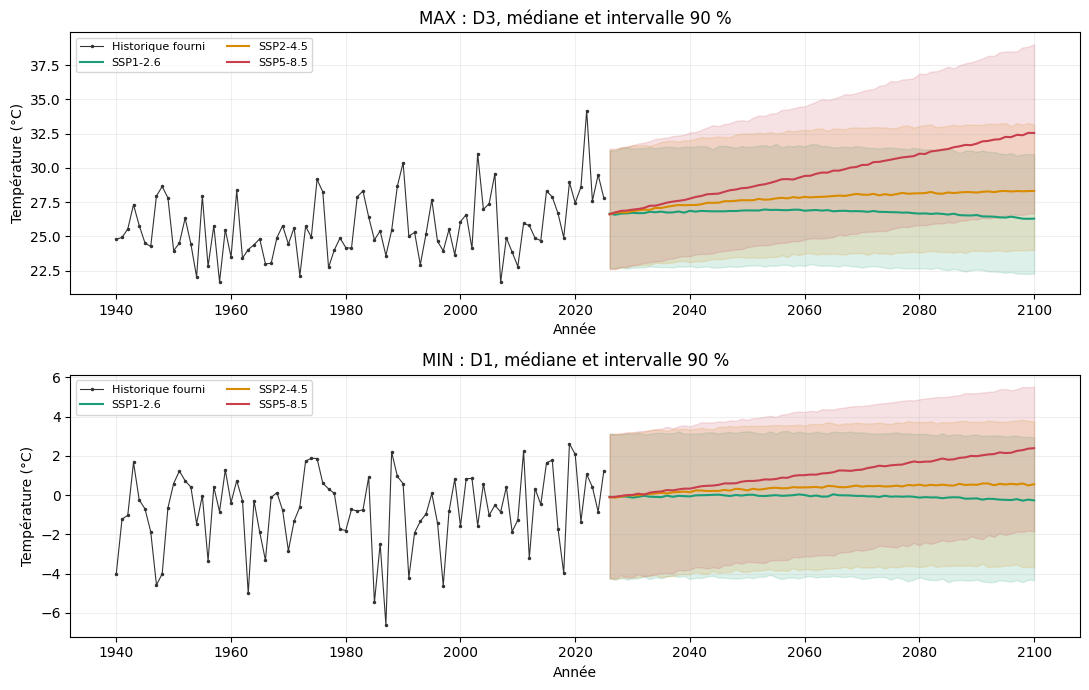

Les trajectoires suivent les scénarios de concentration. Sous SSP1-2.6, la baisse tardive du CO₂ entraîne aussi une baisse de l'ancre instantanée. Le modèle ne représente pas explicitement la mémoire de l'océan ni les autres forçages : cette réversibilité ne doit pas être présentée comme une prévision climatique complète. L'intervalle D3 s'élargit avec l'incertitude de pente ; D1 conserve une forme résiduelle et une échelle fixes, donc peut manquer une évolution de variabilité.

In [20]:
simulations={};lignes=[]
for v in ["max","min"]:
    suite=json.loads((MODELES/f"complet/{v}/suite.json").read_text())
    for j,sc in enumerate(SCENARIOS):
        s=predictive_sample(suite,choix["selected"][v],future[sc],root=RACINE,
            seed=42000+j+100*(v=="min"),independent_years=True)
        assert s.shape==(75,10000) and np.isfinite(s).all()
        simulations[v,sc]=s
        q=np.quantile(s,[.05,.5,.95],axis=1)
        for i,annee in enumerate(future.valid_time.dt.year):
            lignes.append({"variable":v,"scenario":sc,"annee":annee,"q05":q[0,i],"q50":q[1,i],"q95":q[2,i]})
projection=pd.DataFrame(lignes)
fig,axes=plt.subplots(2,1,figsize=(11,7))
couleurs=["#1b9e77","#d98b00","#c83e4d"]
for ax,v in zip(axes,["max","min"]):
    ax.plot(annual.year,annual[v],".-",color="#333333",lw=.8,ms=3,label="Historique fourni")
    for sc,c in zip(SCENARIOS,couleurs):
        s=projection[(projection.variable==v)&(projection.scenario==sc)]
        ax.plot(s.annee,s.q50,color=c,label=sc.upper())
        ax.fill_between(s.annee,s.q05,s.q95,color=c,alpha=.15)
    ax.set(xlabel="Année",ylabel="Température (°C)",title=v.upper()+" : "+choix["selected"][v]+", médiane et intervalle 90 %")
    ax.legend(fontsize=8,ncol=2)
plt.tight_layout();plt.show()
display(Markdown("Les trajectoires suivent les scénarios de concentration. Sous SSP1-2.6, la baisse tardive "
    "du CO₂ entraîne aussi une baisse de l'ancre instantanée. Le modèle ne représente pas explicitement "
    "la mémoire de l'océan ni les autres forçages : cette réversibilité ne doit pas être présentée "
    "comme une prévision climatique complète. L'intervalle D3 s'élargit avec l'incertitude de pente ; "
    "D1 conserve une forme résiduelle et une échelle fixes, donc peut manquer une évolution de variabilité."))

### Distribution de 2100 et risque annuel de 40 °C

$$\widehat p_{2100}=\frac1{10\,000}\sum_j\mathbf1\{T^{(j)}_{2100}>40\}.$$

Pour Tmin, nous donnons de façon analogue $P(T_{2100}<0\,°C)$, un indicateur
de gel pour la variable fournie. Les intervalles binomiaux à 95 % qui suivent
quantifient seulement l'erreur Monte-Carlo conditionnelle aux modèles.
Le mélange des trois réseaux utilise des effectifs équilibrés : les bornes
binomiales sont ici une approximation de cette erreur numérique, distincte
de l'incertitude climatique ou de celle des paramètres.

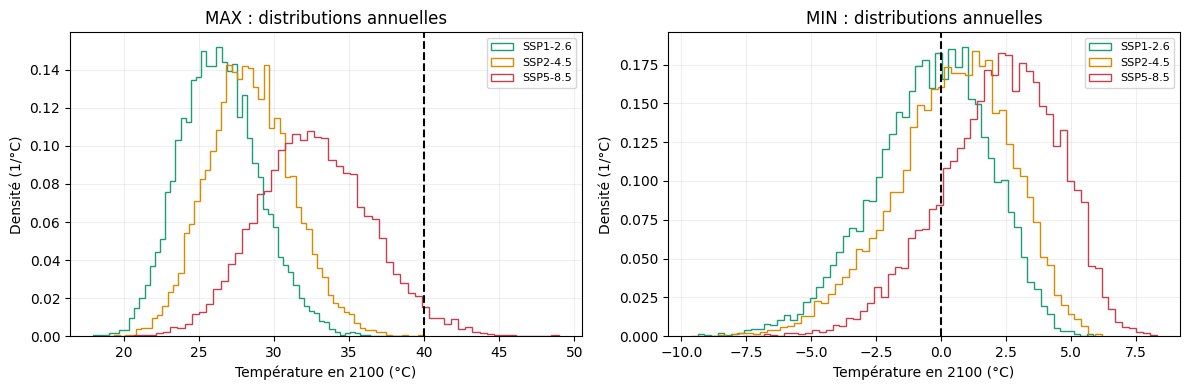

,Variable,Scénario,q05 (°C),médiane (°C),q95 (°C),P en 2100,Nombre sur 10 000,Borne MC basse,Borne MC haute,P au moins une fois
0,max,ssp1-2.6,22.2959,26.2983,30.9991,0.0000,0,0.0000,0.0004,0.0001
1,max,ssp2-4.5,24.0112,28.3161,33.1477,0.0000,0,0.0000,0.0004,0.0022
2,max,ssp5-8.5,26.7045,32.5463,39.0170,0.0301,301,0.0268,0.0336,0.1726
3,min,ssp1-2.6,-4.3247,-0.2662,2.9384,0.5473,5473,0.5375,0.5571,1.0000
4,min,ssp2-4.5,-3.6858,0.5589,3.7583,0.4063,4063,0.3967,0.4160,1.0000
5,min,ssp5-8.5,-1.8355,2.3924,5.5220,0.1666,1666,0.1593,0.1741,1.0000


Sous SSP5-8.5, la simulation remise avec D3 donne environ **3 % par an en 2100**. Les scénarios bas peuvent donner zéro membre au-dessus de 40 °C ; avec 0 sur 10 000, la borne supérieure MC bilatérale à 95 % vaut 0.0369 %. Un zéro simulé ne signifie donc pas une impossibilité physique. Les minima plus doux n'impliquent pas la disparition de tout gel, et ne décrivent pas les microclimats locaux.

In [21]:
probabilites=[]
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,v in zip(axes,["max","min"]):
    for sc,c in zip(SCENARIOS,couleurs):
        s=simulations[v,sc];evenement=s>40 if v=="max" else s<0
        k=int(evenement[-1].sum());n=s.shape[1]
        borne_basse=0. if k==0 else beta.ppf(.025,k,n-k+1)
        borne_haute=1. if k==n else beta.ppf(.975,k+1,n-k)
        q=np.quantile(s[-1],[.05,.5,.95])
        probabilites.append({"variable":v,"scenario":sc,"q05 (°C)":q[0],"médiane (°C)":q[1],"q95 (°C)":q[2],
            "p_2100":k/n,"Nombre sur 10 000":k,"Borne MC basse":borne_basse,"Borne MC haute":borne_haute,
            "p_at_least_one":evenement.any(axis=0).mean()})
        ax.hist(s[-1],bins=60,density=True,histtype="step",color=c,label=sc.upper())
    ax.axvline(40 if v=="max" else 0,color="black",ls="--")
    ax.set(xlabel="Température en 2100 (°C)",ylabel="Densité (1/°C)",title=v.upper()+" : distributions annuelles");ax.legend(fontsize=8)
plt.tight_layout();plt.show()
prob=pd.DataFrame(probabilites)
tableau(prob)
faible=prob[prob.variable=="max"].iloc[0]
display(Markdown(f"Sous SSP5-8.5, la simulation remise avec D3 donne environ **3 % par an en 2100**. "
    f"Les scénarios bas peuvent donner zéro membre au-dessus de 40 °C ; avec 0 sur 10 000, "
    f"la borne supérieure MC bilatérale à 95 % vaut {100*beta.ppf(.975,1,10000):.4f} %. "
    "Un zéro simulé ne signifie donc pas une impossibilité physique. Les minima plus doux "
    "n'impliquent pas la disparition de tout gel, et ne décrivent pas les microclimats locaux."))

### « D'ici 2100 » : une autre probabilité

Nous distinguons l'année 2100 et **au moins un dépassement entre 2026 et
2100**. Avec des paramètres $\theta$ partagés et des innovations annuelles
conditionnellement indépendantes,
$$P(\exists t:T_t>40)=\mathbb E_\theta\!left[1-\prod_{t=2026}^{2100}
F_\theta(40\mid C_t)\right].$$
Nous l'estimons par la proportion de trajectoires ayant au moins un
dépassement. Ce n'est pas $1-\prod_t(1-p_t)$ quand les paramètres incertains
sont partagés. La dépendance entre années compte ; les observations ne nous
permettent pas de vérifier cette hypothèse à 75 ans.

Dans le rendu remis, D3 donne environ **17 %** de trajectoires avec au moins
un dépassement sous SSP5-8.5. Ce nombre est conditionnel au modèle, au
scénario et à l'hypothèse temporelle ; ce n'est pas un risque climatique
connu avec cette précision.

## 8. Ce qui limite le plus les projections

Les probabilités de queue dépendent fortement de l'ancre et de la loi des
résidus. Le tableau suivant compare les méthodes ajustées sur les mêmes
86 années. La référence linéaire en CO₂ peut rester proche sur 2001–2025
tout en projetant beaucoup plus chaud à 946 ppm. Un meilleur CRPS historique
ne suffit donc pas à choisir une loi de queue en 2100.

In [22]:
sensibilite=pd.read_csv(RESULTATS/"sensibilite_projections.csv")
risque=pd.read_csv(RESULTATS/"probabilites.csv")
tableau(risque[(risque.variable=="max")&(risque.scenario=="ssp5-8.5")][["model","p_2100","p_at_least_one"]])
tableau(sensibilite[(sensibilite.variable=="max")&(sensibilite.scenario=="ssp5-8.5")&(sensibilite.year==2100)]
    [["model","q05_C","q50_C","q95_C","probability"]].rename(columns={"q05_C":"q05 (°C)","q50_C":"Médiane (°C)","q95_C":"q95 (°C)","probability":"P(>40 °C)"}))

,Modèle,P en 2100,P au moins une fois
2,D3,0.0301,0.1726
5,Bayes,0.0160,0.0818
8,D1,0.0065,0.0577
11,H1,0.0179,0.1064
14,R_linear,0.1742,0.6807
17,GEV,0.0065,0.0666


,Modèle,q05 (°C),Médiane (°C),q95 (°C),P(>40 °C)
224,D3,26.7045,32.5463,39.0170,0.0301
449,Bayes,27.4421,32.8843,38.3720,0.0160
674,D1,28.7370,32.6139,37.2746,0.0065
899,H1,27.5804,32.8127,38.3765,0.0179
1124,R_linear,34.4049,38.0101,41.5161,0.1742
1349,GEV,26.0762,31.3795,36.9008,0.0065


### Discussion physique et statistique

Notre comparaison montre surtout les limites du petit échantillon. Le
débruiteur apporte une loi résiduelle flexible ; il ne crée pas de nouvelles
observations. Bayes rend explicite une incertitude de tendance, mais sa
contrainte positive et sa vraisemblance normale restent des hypothèses. La
GEV décrit des queues asymétriques, avec une forme peu identifiée. Les
quantiles évitent une loi paramétrique globale, mais leur interpolation et
leurs queues ajoutent aussi des choix.

Le CO₂ historique n'isole pas son effet causal : il accompagne le temps,
tandis que circulation, humidité des sols, aérosols et inertie océanique
ne sont pas modélisés. La valeur 946 ppm est loin des 310–428 ppm observés.
Des intervalles qui propagent la pente n'incluent pas toute l'erreur de
structure ni une modification possible de la variabilité résiduelle.

Le test montre encore un biais froid des maxima et une couverture inférieure
à la valeur nominale pour plusieurs méthodes. Il serait excessif de présenter
nos bandes comme parfaitement calibrées. Les événements au-delà du seuil
q80 sont peu nombreux ; aucun contrôle historique du twCRPS ne démontre la
précision d'une probabilité de 40 °C très éloignée des observations.

Enfin, nous avons modélisé des lois annuelles marginales. Nous n'avons appris
ni une météo quotidienne future, ni une dépendance conjointe entre maximum
et minimum, ni une correction station/maille. Les trajectoires sont un moyen
d'exprimer l'incertitude conditionnelle, pas une prévision des années exactes
où se produiraient les épisodes.

Pour défendre le résultat à l'oral : D3/D1 est notre choix de validation ;
Bayes a le meilleur CRPS Tmax observé sur le test déjà consulté ; H0 ne gagne
pas ; H1 n'apporte pas de gain de validation ; l'écart entre modèles en
2100 est un résultat scientifique à discuter, pas une raison de sélectionner
après coup la projection la plus rassurante.

## 9. Références, reproduction et vérifications

Sources des données : archive du professeur, starter et kit fournis avec le
projet. Les SHA des contributions, les corrections et les réglages sont dans
`reports/audit_contributions.md`, `reports/inventaire_contributions.csv` et
`reports/protocole_commun.md`. Les sources individuelles sont archivées sans
modification. Le manifeste embarqué identifie chaque petite dépendance.

Références méthodologiques :

- [Ho, Jain et Abbeel (2020), DDPM](https://arxiv.org/abs/2006.11239) : diffusion classique étudiée et échec local conservé.
- [Park et al. (2026), débruitage à score propre](https://arxiv.org/abs/2609.38632) : inspiration de D1, adaptation scalaire locale.
- [Lang et al. (2024), AIFS-CRPS](https://arxiv.org/html/2412.15832v1) : score almost fair.
- [Gneiting et Ranjan, Combining Predictive Distributions](https://arxiv.org/abs/1106.1638) : mélange H0 ; ne valide pas H1.
- [Documentation scoringrules](https://scoringrules.readthedocs.io/en/latest/weighted_scores.html) : CRPS pondéré par seuil.
- [GEV non stationnaire en climatologie, ASCMO (2023)](https://ascmo.copernicus.org/articles/9/45/2023/) : covariable CO₂.

Dans un clone : `python -m pip install -r requirements-final.txt`, puis
`python scripts/run_final_team.py --retrain --output rendu_reentraine`.
Dans Colab : ouvrir ce seul notebook, choisir le mode et tout exécuter.
Chaque membre dispose de son propre noyau Colab ; les corrections rédactionnelles
se font sur un fichier maître partagé. Après relecture humaine, ne pas
régénérer ce fichier à partir du script de construction.

### Matrice de conformité au sujet original

| Source | Exigence | Cellules du rendu | Réponse vérifiée |
|---|---|---|---|
| Starter 0–5 | Membres, objectif et quatre axes | introduction | Attribution réelle, deux parties, transparence du test |
| Starter 8,12,20,26 | Imports et accès aux trois jeux | installation,imports | Installation explicite, ressources embarquées, unités et assertions |
| Starter 13–14 | q10/q50/q90 et lissage mensuel | p1-cycle,calcul-cycle | 365 mois/jours, fenêtre circulaire 31 jours, 29 février interpolé |
| Starter 15–16 | Durée et intensité des épisodes | p1-evenements,calcul-vagues | Suites maximales, chronologie réelle, intensité à q50, sensibilité 2/3 jours |
| Starter 17–18 | Diagramme durée/intensité coloré par année | calcul-vagues | Axes en jours/°C, couleur et interprétation |
| Starter 21–22 | Tmax annuel 1940–2025 | p2-historique,series-historiques | Série, lissage descriptif et commentaire physique |
| Starter 23–24 | Corrélation et transformations | correlations | Pearson, log/racine CO₂, lissages T, limites |
| Starter 25–27 | Prévisions probabilistes récentes, trois SSP, équations | denoiseur,code-denoiseur,code-entrainement,calcul-projections | PyTorch, mini-entraînement réel, D1/D3, lois annuelles 2026–2100 |
| Starter 28–29 | Distribution 2100 et P(>40°C) | distribution-probabilites,risque-cumule | Trois distributions, probabilités annuelles/cumulées, bornes MC |
| Starter 30–31 | Même étude pour Tmin | series-historiques,correlations,tableau-validation,calcul-projections,distribution-probabilites | Historique, corrélations, scores, projections et gel |
| Critère 1 | Qualité du code | calcul-cycle,calcul-vagues,code-scores,code-bayes,code-quantiles,code-gev,code-denoiseur | Fonctions courtes commentées ; matrice séparée |
| Critère 2 | Qualité des sorties et unités | tableau-validation,tableau-test,calcul-projections,distribution-probabilites | °C, ppm, jours, densité 1/°C et probabilités sans unité |
| Critère 3 | Méthode mathématique en LaTeX | metriques,modeles-statistiques,quantiles,gev,denoiseur,hybrides | Hypothèses, objectifs, génération et normalisation |
| Critère 4 | Discussion physique | donnees,correlations,incertitudes,discussion | Saisonnalité, causalité, inertie, sous-couverture et extrapolation |
| Mission équipe | CRPS/twCRPS, H0/H1, ancres et échecs | metriques,hybrides,ablation-hybrides,test-exploratoire,echecs,tableau-sensibilites | Résultats favorables/défavorables et méthodes complètes distingués |
| Mission équipe | Reproductibilité et séparation des phases | ressources,validation,controles-recalcules | Noyau propre, manifestes, assertions et kit original réexécuté |

In [23]:
assert len(vagues)>0 and score_recalcule is not None
assert all(np.isfinite(s).all() for s in simulations.values())
assert set(projection.scenario)==set(SCENARIOS)
assert len(projection)==2*3*75
duree=time.perf_counter()-DEBUT_EXECUTION
preuve={"status":"completed", "mode":MODE, "seconds":duree,
    "python":sys.version.split()[0],"torch":torch.__version__,"numpy":np.__version__,
    "bundle_sha256":hashlib.sha256(archive).hexdigest(), "n_resources":len(empreintes),
    "heatwaves":len(vagues),"score_max":score_recalcule[0],"score_min":score_recalcule[1],
    "selection":choix["selected"],"projection_rows":len(projection),"working_directory":str(Path.cwd()),
    "fresh_resources_directory":str(RACINE),"test_previously_consulted":True}
(Path.cwd()/"verification_notebook.json").write_text(json.dumps(preuve,ensure_ascii=False,indent=2),encoding="utf-8")
print(f"Vérification terminée : {len(vagues)} événements, 6 ensembles 75×10 000, kit admissible, {duree:.1f} s.")

Vérification terminée : 421 événements, 6 ensembles 75×10 000, kit admissible, 28.2 s.
